<a href="https://colab.research.google.com/github/Mitochondrion3000/epic-competiton/blob/main/epic_eda_explained(%D0%BB%D1%83%D1%87%D1%88%D0%B8%D0%B9_%D0%B2%D0%B0%D1%80%D0%B8%D0%B0%D0%BD%D1%82).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# EDA для EPIC (датасет Nematostella, jaNemVect1.1)

Ноутбук **без GPU**: только чтение данных и графики. Каждый раздел отвечает на конкретный вопрос, от которого зависит, как улучшать модель.

| Раздел | Вопрос | Какое решение зависит от ответа |
|---|---|---|
| A. Геном | Есть ли в fasta строчные буквы (маска повторов)? Как различаются контиги по GC? | Подавать ли маску повторов модели; нужна ли валидация по нескольким хромосомам |
| B. Метки и реплики | Насколько согласованы две реплики? Много ли позиций с одним прочтением? | Потолок качества (Spearman не может быть выше воспроизводимости данных); нужно ли чистить метки |
| C. Whitelist и тест | Чем whitelist отличается от остального генома? Совпадает ли доля положительных в train и в тесте? | На каких позициях учить и проверять модель |
| D. Пространственная структура | Как кучкуются позиции, есть ли пары плюс/минус? | Нужна ли точность до одного нуклеотида, или достаточно «примерного» места |
| E. Последовательность вокруг позиций | Видны ли мотивы, различаются ли слабые и сильные позиции? | Насколько метки шумные; чему модель в принципе может научиться |
| F. Простой базовый уровень (PWM) | Сколько даёт модель из одного мотива без нейросети? | Реальная ценность CNN относительно тривиального метода |

In [ ]:
# Настройка и загрузка данных (если архив уже скачан, повторно не качается)
import os, re, gzip, glob, tarfile, requests
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import average_precision_score
from scipy.stats import spearmanr

plt.rcParams["figure.dpi"] = 110
DATA_DIR = "/content/epic"; BASE = f"{DATA_DIR}/jaNemVect1.1"
os.makedirs(DATA_DIR, exist_ok=True)
if not os.path.isdir(BASE):
    rec = requests.get("https://zenodo.org/api/records/22285753", timeout=60).json()
    f = [x for x in rec["files"] if "jaNemVect1.1" in x["key"]][0]
    dst = f"{DATA_DIR}/{os.path.basename(f['key'])}"
    with requests.get(f["links"]["self"], stream=True, timeout=120) as r:
        r.raise_for_status()
        with open(dst, "wb") as fh:
            for chunk in r.iter_content(1 << 20): fh.write(chunk)
    tarfile.open(dst).extractall(DATA_DIR)
print(sorted(os.listdir(BASE)))

/tmp/ipykernel_824/3345216038.py:19: DeprecationWarning: Python 3.14 will, by default, filter extracted tar archives and reject files or modify their metadata. Use the filter argument to control this behavior.
  tarfile.open(dst).extractall(DATA_DIR)


['for_participants', 'genome', 'ground_truth', 'scoring']


In [ ]:
# Паспорт датасета: что за организм и какие контиги (файл genome/assembly_report.txt)
rep = f"{BASE}/genome/assembly_report.txt"
with open(rep) as fh: lines = fh.read().splitlines()
print("\n".join(l for l in lines if l.startswith("# ") and ":" in l)[:2500])   # вид, имя сборки, организация, тип сборки
cols = ["Sequence-Name", "Sequence-Role", "Assigned-Molecule", "Molecule-Type", "GenBank-Accn", "Relationship", "RefSeq-Accn", "Assembly-Unit", "Sequence-Length", "UCSC-name"]
ar = pd.read_csv(rep, sep="\t", header=None, comment="#", names=cols, usecols=range(10), engine="python", on_bad_lines="skip")
print("\nроли последовательностей:"); print(ar["Sequence-Role"].value_counts().to_string())
print("\nпервые строки таблицы:"); print(ar[["Sequence-Name", "Sequence-Role", "Assigned-Molecule", "RefSeq-Accn", "Sequence-Length"]].head(20).to_string(index=False))

# Assembly name:  jaNemVect1.1
# Organism name:  Nematostella vectensis (starlet sea anemone)
# Taxid:          45351
# BioSample:      SAMEA8534429
# BioProject:     PRJEB51373
# Submitter:      WELLCOME SANGER INSTITUTE
# Date:           2022-03-23
# Assembly type:  haploid (principal pseudohaplotype of diploid)
# Release type:   major
# Assembly level: Chromosome
# Genome representation: full
# WGS project:    CAKOAW01
# Assembly method: various
# Genome coverage: 53x
# Sequencing technology: PacBio,Arima2
# RefSeq category: Reference Genome
# GenBank assembly accession: GCA_932526225.1
# RefSeq assembly accession: GCF_932526225.1
# RefSeq assembly and GenBank assemblies identical: no
# Linked assembly: GCA_932526215.1 (alternate pseudohaplotype of diploid)

роли последовательностей:
Sequence-Role
unplaced-scaffold     32
assembled-molecule    16

первые строки таблицы:
Sequence-Name      Sequence-Role Assigned-Molecule    RefSeq-Accn  Sequence-Length
      SUPER_1 assembled-molecul

## A. Геном
Читаем fasta, сохраняя **регистр букв**: в основной модели я его выбрасывал (строчные и прописные считались одинаково).
Если геном «мягко маскирован», строчные буквы отмечают повторы, а это может быть полезно и для модели, и для понимания, какие участки отбирает whitelist.

                длина_Мб      GC  доля_N  доля_строчных
контиг                                                 
NC_064034.1      22.1686  0.4091  0.0001         0.2484
NC_064035.1      22.0320  0.4080  0.0001         0.2407
NC_064036.1      20.7938  0.4083  0.0001         0.2576
NC_064037.1      19.3197  0.4076  0.0000         0.2904
NC_064038.1      19.0006  0.4080  0.0001         0.3897
NC_064039.1      18.0961  0.4096  0.0000         0.2545
NC_064040.1      17.8659  0.4067  0.0001         0.3091
NC_064041.1      17.3630  0.4100  0.0003         0.3270
NC_064042.1      17.3270  0.4107  0.0001         0.2729
NC_064043.1      16.5938  0.4052  0.0001         0.3004
NC_064044.1      16.4098  0.4039  0.0002         0.3733
NC_064045.1      16.3883  0.4058  0.0004         0.3932
NC_064046.1      16.1396  0.4035  0.0001         0.3270
NC_064047.1      15.3723  0.4104  0.0001         0.3248
NC_064048.1      13.7174  0.4002  0.0002         0.3682
NW_026019251.1    0.0963  0.2806  0.0000        

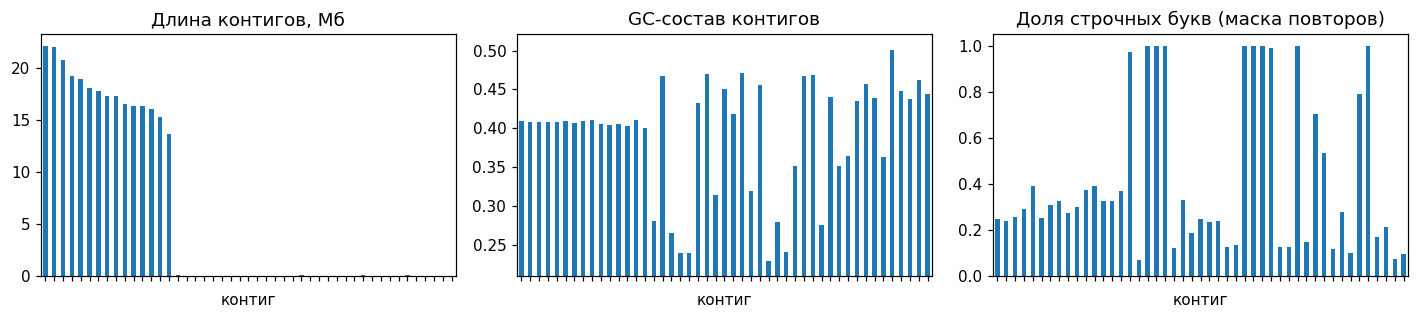

Как читать: если доля строчных букв около нуля, маски повторов в файле нет; если заметна (десятки процентов), её можно подать модели как 5-й вход.


In [ ]:
LUT = np.full(256, 4, np.uint8)
for i, b in enumerate("ACGT"):
    LUT[ord(b)] = i; LUT[ord(b.lower())] = i
COMP = np.array([3, 2, 1, 0, 4], np.uint8)

def read_fasta_case(path):
    # возвращает два словаря: коды 0-4 и булева маска строчных букв (мягкая маска повторов)
    op = gzip.open if path.endswith(".gz") else open
    codes, lower, name, chunks = {}, {}, None, []
    def flush():
        raw = np.frombuffer("".join(chunks).encode(), np.uint8)
        codes[name] = LUT[raw]; lower[name] = raw >= 97
    with op(path, "rt") as fh:
        for line in fh:
            if line.startswith(">"):
                if name is not None: flush()
                name = line[1:].split()[0]; chunks = []
            else: chunks.append(line.strip())
    if name is not None: flush()
    return codes, lower

codes, lower = read_fasta_case(f"{BASE}/genome/genome.fa.gz")
rows = []
for c in codes:
    x = codes[c]; valid = x < 4
    rows.append({"контиг": c, "длина_Мб": len(x) / 1e6,
                 "GC": float(((x == 1) | (x == 2))[valid].mean()),
                 "доля_N": float((~valid).mean()), "доля_строчных": float(lower[c].mean())})
genome_tbl = pd.DataFrame(rows).set_index("контиг")
print(genome_tbl.round(4).to_string())

fig, ax = plt.subplots(1, 3, figsize=(13, 3))
genome_tbl["длина_Мб"].plot.bar(ax=ax[0], title="Длина контигов, Мб")
genome_tbl["GC"].plot.bar(ax=ax[1], title="GC-состав контигов"); ax[1].set_ylim(genome_tbl.GC.min() - 0.02, genome_tbl.GC.max() + 0.02)
genome_tbl["доля_строчных"].plot.bar(ax=ax[2], title="Доля строчных букв (маска повторов)")
for a in ax: a.set_xticklabels([])
plt.tight_layout(); plt.show()
print("Как читать: если доля строчных букв около нуля, маски повторов в файле нет; если заметна (десятки процентов), её можно подать модели как 5-й вход.")

                                                контигов  всего_Мб
роль                                                              
test (оценивается в соревновании)                      3      51.9
train (есть метки)                                    12     216.7
несобранный фрагмент (NW_...), не используется        32       0.8

тестовые контиги: ['NC_064037.1', 'NC_064044.1', 'NC_064046.1']
обучающие хромосомы: ['NC_064034.1', 'NC_064035.1', 'NC_064036.1', 'NC_064038.1', 'NC_064039.1', 'NC_064040.1', 'NC_064041.1', 'NC_064042.1', 'NC_064043.1', 'NC_064045.1', 'NC_064047.1', 'NC_064048.1']


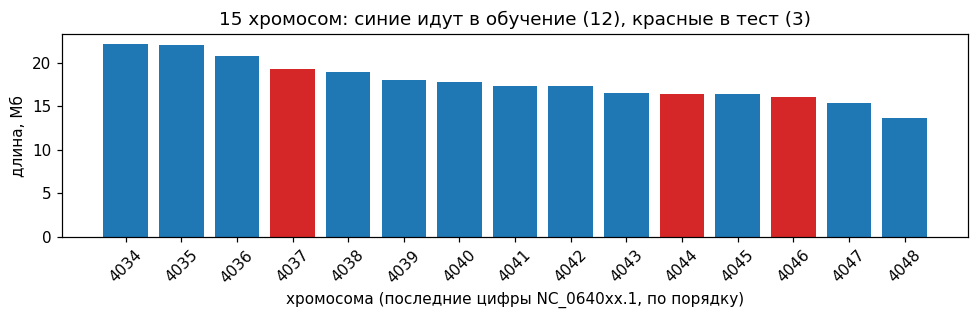

In [ ]:
# Роли контигов: какие хромосомы идут в обучение, какие в тест, какие остаются без меток
tpl_chroms = set(pd.read_csv(f"{BASE}/for_participants/template.test.bed.gz", sep="\t", header=None, usecols=[0], names=["c"], dtype=str)["c"])
lab_chroms = set()
for r in ("r1", "r2"):
    lab_chroms |= set(pd.read_csv(f"{BASE}/for_participants/csRNA-{r}-train.bed.gz", sep="\t", header=None, usecols=[0], names=["c"], dtype=str)["c"])
def role_of(c):
    if c in tpl_chroms: return "test (оценивается в соревновании)"
    if c in lab_chroms: return "train (есть метки)"
    return "несобранный фрагмент (NW_...), не используется" if c.startswith("NW_") else "хромосома без меток"
genome_tbl["роль"] = [role_of(c) for c in genome_tbl.index]
print(genome_tbl.groupby("роль").agg(контигов=("длина_Мб", "size"), всего_Мб=("длина_Мб", "sum")).round(1).to_string())
print("\nтестовые контиги:", sorted(tpl_chroms)); print("обучающие хромосомы:", sorted(lab_chroms))
chroms = genome_tbl[genome_tbl.index.str.startswith("NC_")].copy(); chroms["номер"] = range(1, len(chroms) + 1)
colors = chroms["роль"].map({"train (есть метки)": "tab:blue", "test (оценивается в соревновании)": "tab:red"}).fillna("gray")
fig, ax = plt.subplots(figsize=(9, 3))
ax.bar(chroms["номер"], chroms["длина_Мб"], color=colors)
ax.set_xticks(chroms["номер"]); ax.set_xticklabels([c[-6:-2] for c in chroms.index], rotation=45)
ax.set_xlabel("хромосома (последние цифры NC_0640xx.1, по порядку)"); ax.set_ylabel("длина, Мб")
ax.set_title("15 хромосом: синие идут в обучение (12), красные в тест (3)")
plt.tight_layout(); plt.show()

### Что это за организм и какие хромосомы (по вашему запуску)

**Организм.** Датасет `jaNemVect1.1` относится к *Nematostella vectensis*, звёздчатой морской анемоне (тип Cnidaria, стрекающие). Это название указано на странице соревнования, где этот датасет выдан как учебная копия оценки, а число хромосом совпадает с известным кариотипом вида (15). Точное название вида и имя сборки подтверждает ячейка «Паспорт датасета» выше (в ней печатается `assembly_report.txt`).

**Контиги: всего 47, 269,4 Мб.**
- **15 хромосом** (`NC_064034.1`–`NC_064048.1`, номера по убыванию длины, от 22,2 до 13,7 Мб, вместе 268,6 Мб).
- **32 несобранных фрагмента** (`NW_026019251.1`–`NW_026019282.1`), каждый от 3 до 99 кб, вместе около 0,8 Мб. Это куски, которые не удалось встроить в хромосомы.

**Кто для чего используется.**
- **Обучающие (12 хромосом с метками):** NC_064034, 035, 036, 038, 039, 040, 041, 042, 043, 045, 047, 048.
- **Тестовые (3 хромосомы, по ним считается оценка):** NC_064037.1, NC_064044.1, NC_064046.1. Меток для них в обучающих файлах нет.
- **Фрагменты NW_...:** ни меток, ни тестовых интервалов, в работе не участвуют.

### Как читать три графика выше (длины, GC, строчные буквы)

Каждый столбик на всех трёх графиках это один из 47 контигов, в одном и том же порядке (сначала 15 хромосом, затем 32 фрагмента).

1. **«Длина контигов, Мб»**: 15 высоких столбиков и почти невидимые остальные. Геном по сути состоит из 15 хромосом, фрагменты в сумме занимают около 0,3%.
2. **«GC-состав»**: у всех 15 хромосом 40,0–41,1% G+C, то есть геном AT-богатый и очень ровный. У фрагментов GC скачет от 23% до 50%: на крошечных кусках (в основном повторах) статистика случайна, и сравнивать их с хромосомами нельзя.
3. **«Доля строчных букв»**: в fasta есть мягкая маска повторов. У хромосом строчных 24–39%, то есть почти треть генома помечена как повторы. У многих фрагментов 100% (они целиком повторы), поэтому их и не размечали. Вывод: маску повторов можно использовать как дополнительный вход модели (в основном ноутбуке регистр букв сейчас выбрасывается).

## B. Метки и реплики
Две реплики эксперимента csRNA-seq дают независимые измерения одних и тех же позиций.
**Согласованность реплик задаёт потолок**: никакая модель не должна ожидать корреляции с одной репликой выше, чем реплики коррелируют друг с другом.

строк (позиция-цепь) в фильтрованных  r1/r2: 94425 172973
строк в нефильтрованных              r1/r2: 100113 184962
фильтрация оставляет r1: 94.3%, r2: 93.5% строк; суммы счётчиков: r1 85.1%, r2 78.4%
позиции: только r1 48586, только r2 127134, в обеих 45839 (из 221559)
позиций с суммарным счётом 1: 52.3%; со счётом >= 10: 9.6%
Spearman между репликами: на объединении позиций (с нулями) -0.027; только на позициях, где есть в обеих: 0.702


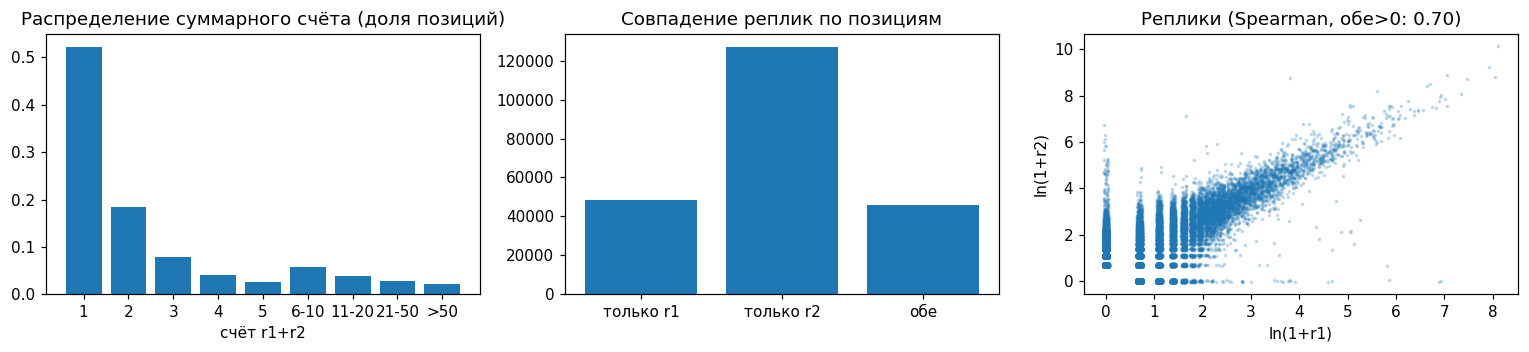

Как читать: если большинство позиций имеет счёт 1 и присутствует только в одной реплике, это в основном шум. Корреляция реплик показывает потолок для Spearman нашей модели.


In [ ]:
def read_bed6(path):
    return pd.read_csv(path, sep="\t", header=None, usecols=[0, 1, 4, 5],
                       names=["chrom", "start", "val", "strand"], dtype={"chrom": str, "strand": str})

fp = f"{BASE}/for_participants"
r1, r2 = read_bed6(f"{fp}/csRNA-r1-train.bed.gz"), read_bed6(f"{fp}/csRNA-r2-train.bed.gz")
u1, u2 = read_bed6(f"{fp}/csRNA-r1-train-unfiltered.bed.gz"), read_bed6(f"{fp}/csRNA-r2-train-unfiltered.bed.gz")
print("строк (позиция-цепь) в фильтрованных  r1/r2:", len(r1), len(r2))
print("строк в нефильтрованных              r1/r2:", len(u1), len(u2))
print(f"фильтрация оставляет r1: {len(r1)/len(u1):.1%}, r2: {len(r2)/len(u2):.1%} строк; суммы счётчиков: "
      f"r1 {r1.val.sum()/u1.val.sum():.1%}, r2 {r2.val.sum()/u2.val.sum():.1%}")

lab = (r1.rename(columns={"val": "c1"}).merge(r2.rename(columns={"val": "c2"}), on=["chrom", "start", "strand"], how="outer")
         .fillna({"c1": 0, "c2": 0}))
lab["tot"] = lab.c1 + lab.c2
only1, only2, both = int(((lab.c1 > 0) & (lab.c2 == 0)).sum()), int(((lab.c2 > 0) & (lab.c1 == 0)).sum()), int(((lab.c1 > 0) & (lab.c2 > 0)).sum())
print(f"позиции: только r1 {only1}, только r2 {only2}, в обеих {both} (из {len(lab)})")
print(f"позиций с суммарным счётом 1: {(lab.tot == 1).mean():.1%}; со счётом >= 10: {(lab.tot >= 10).mean():.1%}")
rho_union = spearmanr(lab.c1, lab.c2).correlation
b = lab[(lab.c1 > 0) & (lab.c2 > 0)]
rho_both = spearmanr(b.c1, b.c2).correlation
print(f"Spearman между репликами: на объединении позиций (с нулями) {rho_union:.3f}; только на позициях, где есть в обеих: {rho_both:.3f}")

fig, ax = plt.subplots(1, 3, figsize=(14, 3.3))
bins = [1, 2, 3, 4, 5, 6, 11, 21, 51, np.inf]; labs = ["1", "2", "3", "4", "5", "6-10", "11-20", "21-50", ">50"]
ax[0].bar(labs, pd.cut(lab.tot, bins, right=False).value_counts(normalize=True, sort=False).values)
ax[0].set_title("Распределение суммарного счёта (доля позиций)"); ax[0].set_xlabel("счёт r1+r2")
ax[1].bar(["только r1", "только r2", "обе"], [only1, only2, both]); ax[1].set_title("Совпадение реплик по позициям")
s = lab.sample(min(len(lab), 80000), random_state=0)
ax[2].scatter(np.log1p(s.c1) + np.random.uniform(-.05, .05, len(s)), np.log1p(s.c2) + np.random.uniform(-.05, .05, len(s)), s=2, alpha=.2)
ax[2].set_xlabel("ln(1+r1)"); ax[2].set_ylabel("ln(1+r2)"); ax[2].set_title(f"Реплики (Spearman, обе>0: {rho_both:.2f})")
plt.tight_layout(); plt.show()
print("Как читать: если большинство позиций имеет счёт 1 и присутствует только в одной реплике, это в основном шум. "
      "Корреляция реплик показывает потолок для Spearman нашей модели.")

### Как читать графики про метки и реплики

**Что в данных.** Каждая строка в файлах меток это позиция генома на одной из двух цепей, где найдено начало РНК, плюс число прочтений в этой позиции. Эксперимент выполнен в двух повторностях (реплики r1 и r2). Позиция «положительная», если в сумме по репликам есть хотя бы одно прочтение.

**Цифры из вывода.**
- r1: 94 425 позиций, r2: 172 973 (вторая реплика прочитана глубже). Всего 221 559 разных позиций-цепей.
- Нефильтрованных позиций 100 113 и 184 962. Фильтрация убирает 5,7% (r1) и 6,5% (r2) позиций, но при этом 14,9% и 21,6% всех прочтений: значит, удалены в основном позиции с очень большим числом прочтений (возможно, артефакты, это мой вывод по цифрам, а не из документации).
- Только в r1: 48 586, только в r2: 127 134, в обеих: 45 839.
- 52,3% позиций имеют суммарный счёт 1; со счётом ≥10 только 9,6%.

**График 1 («Распределение суммарного счёта»).** По оси X сумма прочтений r1+r2 в позиции, по оси Y доля позиций. Больше половины положительных позиций это одно прочтение, хвост тянется до десятков и сотен. То есть среди «положительных» очень много слабых позиций.

**График 2 («Совпадение реплик»).** Столбики показывают, сколько позиций нашла только r1, только r2 или обе. Обе реплики подтверждают лишь 21% позиций (45 839 из 221 559). Большинство позиций видит только одна реплика, в основном r2, у неё больше прочтений. Для слабых позиций присутствие или отсутствие в конкретной реплике во многом случайно.

**График 3 («Реплики», точки).** Каждая точка это позиция: X = ln(1+счёт в r1), Y = ln(1+счёт в r2). Точки образуют вертикальные и горизонтальные полосы, потому что счёты целые. Полоса на оси X=0 это позиции, которые есть только в r2, полоса на Y=0 только в r1. Облако вдоль диагонали это позиции, которые есть в обеих: чем сильнее позиция, тем лучше совпадают реплики. Spearman по ним 0,70.

**Про строку «Spearman на объединении = −0,027».** Это артефакт отбора: в таблице есть только позиции, замеченные хотя бы в одной реплике, а в другой у них ноль, поэтому корреляция по такой выборке бессмысленна. Содержательное число 0,70, но оно завышено, так как считается только по позициям, найденным в обеих репликах.

**Что это значит для модели.** Согласие реплик по силе (0,70 на подтверждённых позициях) заметно выше, чем у нашей модели на тесте (Spearman 0,385), так что запас по силе есть. А вот «положительные» метки шумные из-за слабых позиций, это ограничивает AUPRC.

предсказатель  порог счёта  выбрано  precision  recall
   c1 -> c2>0            1    94425      0.485   0.265
   c1 -> c2>0            2    37109      0.775   0.166
   c1 -> c2>0            3    22275      0.922   0.119
   c1 -> c2>0            5    13075      0.982   0.074
   c1 -> c2>0           10     6698      0.990   0.038
   c1 -> c2>0           20     3392      0.985   0.019
   c2 -> c1>0            1   172973      0.265   0.485
   c2 -> c1>0            2    89585      0.424   0.402
   c2 -> c1>0            3    54945      0.586   0.341
   c2 -> c1>0            5    31529      0.787   0.263
   c2 -> c1>0           10    16936      0.925   0.166
   c2 -> c1>0           20     9133      0.970   0.094


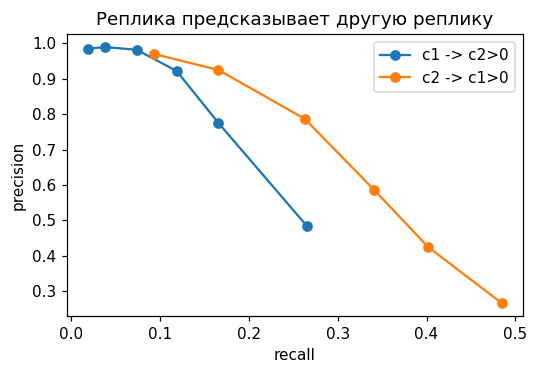

In [ ]:
# Реплика как «предсказатель» другой реплики: насколько хорошо r1 угадывает, что в r2 тоже есть прочтения (и наоборот)
# Это не модель по последовательности, а оценка воспроизводимости данных: показывает порядок величин precision и recall в самих данных.
rows = []
for a, b in (("c1", "c2"), ("c2", "c1")):
    for t in (1, 2, 3, 5, 10, 20):
        sel = lab[a] >= t
        hit = lab.loc[sel, b] > 0
        rows.append({"предсказатель": f"{a} -> {b}>0", "порог счёта": t, "выбрано": int(sel.sum()),
                     "precision": round(float(hit.mean()), 3), "recall": round(float(hit.sum() / (lab[b] > 0).sum()), 3)})
rep_tbl = pd.DataFrame(rows); print(rep_tbl.to_string(index=False))
fig, ax = plt.subplots(figsize=(5, 3.5))
for k, g in rep_tbl.groupby("предсказатель"): ax.plot(g.recall, g.precision, "o-", label=k)
ax.set_xlabel("recall"); ax.set_ylabel("precision"); ax.set_title("Реплика предсказывает другую реплику"); ax.legend()
plt.tight_layout(); plt.show()

**Что показывает эта таблица.** Если брать положительные позиции одной реплики и смотреть, сколько из них подтверждает другая, то при пороге 1 получается точность примерно 48% (r1→r2) и 27% (r2→r1) при полноте 27% и 48%. С ростом порога (сильные позиции) точность быстро растёт. Это не потолок для модели по последовательности (реплики измеряют одну и ту же клетку, а модель видит только ДНК), но задаёт порядок величин: в самих данных precision на уровне десятков процентов достижима, а у модели AUPRC сейчас 0,047.

## C. Whitelist и сравнение train с тестом
В тесте оценка идёт **только по позициям whitelist** (в шаблоне те же интервалы). Если whitelist заметно отличается от всего генома
(по доле положительных, GC, повторам), то обучать и проверять модель «по всему геному» значит оптимизировать не ту задачу.

совпадение интервалов whitelist.test и template.test (по тройкам chrom,start,end): 100.0%
               Мб  whitelist_%  позиций_внутри  позиций_вне  плотность_внутри_на_Мб  плотность_вне_на_Мб
контиг                                                                                                  
NC_064034.1  22.2         76.6           23006            0                  1355.3                  0.0
NC_064035.1  22.0         75.9           30289            0                  1810.6                  0.0
NC_064036.1  20.8         76.0           25725            0                  1627.6                  0.0
NC_064038.1  19.0         66.4           14482            0                  1148.5                  0.0
NC_064039.1  18.1         76.5           21534            0                  1555.6                  0.0
NC_064040.1  17.9         72.9           18631            0                  1430.3                  0.0
NC_064041.1  17.4         69.5           13698            0           

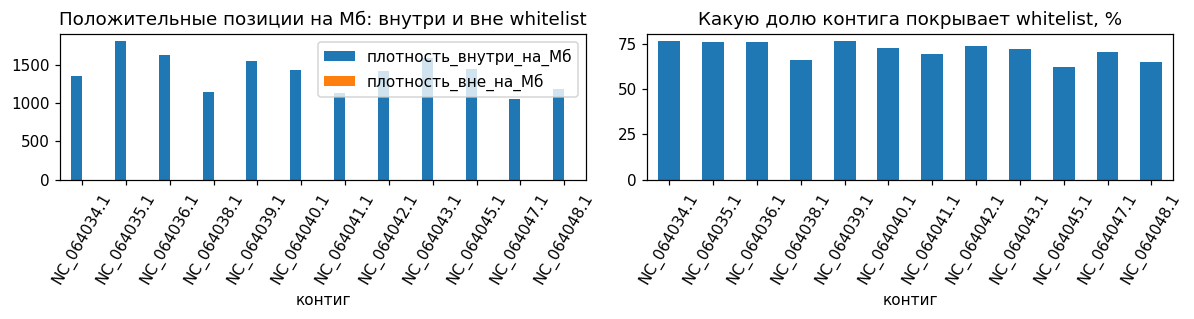

Как читать: если плотность внутри whitelist сильно выше, чем вне, whitelist отбирает «осмысленные» участки; тогда обучать и проверять модель нужно в первую очередь на них. Сравните три доли положительных: если они сильно различаются, метрика AUPRC на val и на тесте несопоставима.


In [ ]:
def read_bed3(path):
    return pd.read_csv(path, sep="\t", header=None, usecols=[0, 1, 2], names=["chrom", "start", "end"], dtype={"chrom": str})

wl_tr, wl_te = read_bed3(f"{fp}/whitelist.train.bed.gz"), read_bed3(f"{fp}/whitelist.test.bed.gz")
tb = pd.read_csv(f"{fp}/template.test.bed.gz", sep="\t", header=None, names=["chrom", "start", "end", "name", "score", "strand"],
                 dtype={"chrom": str, "strand": str})
tb["len"] = tb.end - tb.start
print("совпадение интервалов whitelist.test и template.test (по тройкам chrom,start,end):",
      f"{len(set(zip(wl_te.chrom, wl_te.start, wl_te.end)) & set(zip(tb.chrom, tb.start, tb.end))) / len(set(zip(wl_te.chrom, wl_te.start, wl_te.end))):.1%}")

lab_contigs = sorted(set(lab.chrom) & set(codes))
inwl = {c: np.zeros(len(codes[c]), bool) for c in lab_contigs}
for c, s, e in zip(wl_tr.chrom, wl_tr.start, wl_tr.end):
    if c in inwl: inwl[c][s:e] = True
posrows = {c: d for c, d in lab.groupby("chrom") if c in inwl}

rows = []
for c in lab_contigs:
    L = len(codes[c]); wl_len = int(inwl[c].sum()); d = posrows[c]
    inside = int(inwl[c][d.start.values].sum())
    rows.append({"контиг": c, "Мб": L / 1e6, "whitelist_%": 100 * wl_len / L,
                 "позиций_внутри": inside, "позиций_вне": len(d) - inside,
                 "плотность_внутри_на_Мб": inside / max(wl_len, 1) * 1e6, "плотность_вне_на_Мб": (len(d) - inside) / max(L - wl_len, 1) * 1e6})
wl_tbl = pd.DataFrame(rows).set_index("контиг")
print(wl_tbl.round(1).to_string())

# GC и повторы внутри и вне whitelist (по всем размеченным контигам)
def agg(mask_fn):
    gi = gt_ = ni = nt = 0
    out = {}
    for tag in ("внутри", "вне"):
        g = v = lw = tot = 0
        for c in lab_contigs:
            m = inwl[c] if tag == "внутри" else ~inwl[c]
            x = codes[c][m]; valid = x < 4
            g += int(((x == 1) | (x == 2))[valid].sum()); v += int(valid.sum())
            lw += int(lower[c][m].sum()); tot += int(m.sum())
        out[tag] = {"GC": g / max(v, 1), "доля_строчных": lw / max(tot, 1)}
    return pd.DataFrame(out)
print(agg(None).round(4))

# доли положительных: весь train-геном, train внутри whitelist, тест (позиция-цепь)
tot_len = sum(len(codes[c]) for c in lab_contigs); wl_len_all = sum(int(m.sum()) for m in inwl.values())
rows_in = sum(int(inwl[c][d.start.values].sum()) for c, d in posrows.items())
gt = pd.read_csv(f"{BASE}/ground_truth/csRNA-test.txt.gz", header=None, dtype=np.float32)[0].values
print(f"доля положительных (на позицию-цепь): весь train {len(lab)/(2*tot_len):.2e} | train внутри whitelist {rows_in/(2*wl_len_all):.2e} | тест {(gt>0).mean():.2e}")
print("значения в тесте (топ-8):", dict(pd.Series(gt[gt > 0]).value_counts().head(8)))
print("значения в train (топ-8, сумма реплик):", dict(lab.tot.value_counts().head(8)))

fig, ax = plt.subplots(1, 2, figsize=(11, 3))
w = wl_tbl[["плотность_внутри_на_Мб", "плотность_вне_на_Мб"]]; w.plot.bar(ax=ax[0], title="Положительные позиции на Мб: внутри и вне whitelist"); ax[0].set_xticklabels(wl_tbl.index, rotation=60)
wl_tbl["whitelist_%"].plot.bar(ax=ax[1], title="Какую долю контига покрывает whitelist, %"); ax[1].set_xticklabels(wl_tbl.index, rotation=60)
plt.tight_layout(); plt.show()
print("Как читать: если плотность внутри whitelist сильно выше, чем вне, whitelist отбирает «осмысленные» участки; "
      "тогда обучать и проверять модель нужно в первую очередь на них. Сравните три доли положительных: если они сильно различаются, "
      "метрика AUPRC на val и на тесте несопоставима.")

### Как читать графики про whitelist

**Что такое whitelist.** Список интервалов, где в соревновании считается оценка. Для теста он совпадает с `template.test.bed` на 100% (проверено в выводе).

**Левый график («Положительные позиции на Мб…»).** Для каждой обучающей хромосомы показана плотность размеченных позиций на мегабазу внутри whitelist: 1050–1810 на Мб. Оранжевых столбиков (вне whitelist) на графике нет, потому что **вне whitelist нет ни одной размеченной позиции ни на одной хромосоме** (колонка `позиций_вне` равна 0 во всех строках).

**Правый график («Какую долю контига покрывает whitelist»).** Whitelist занимает 62–77% длины каждой хромосомы, то есть от четверти до трети хромосомы в нём отсутствует.

**Остальные числа из вывода.**
- Строчных букв (повторов) внутри whitelist 19%, снаружи 58%. GC почти одинаков: 40,3% внутри и 41,9% снаружи. Значит, whitelist вырезает в основном повторяющиеся участки (это вывод по маске, в документации я его не проверял).
- Доля положительных на позицию-цепь: весь train 5,1·10⁻⁴; train внутри whitelist 7,1·10⁻⁴; тест 7,4·10⁻⁴. Внутри whitelist доля почти равна тестовой, а по всему геному она ниже на 30%: поэтому val-метрика из основного ноутбука (считается по всему геному) была несопоставима с тестом.
- Значения счётчиков в тесте и в train распределены одинаково: в тесте 52,3% позиций со счётом 1, в train тоже 52,3% (28 157 из 53 813 и 115 780 из 221 559). Тест размечен тем же способом, что и train (сумма двух реплик).

**Главный вывод для модели.** Вне whitelist нет меток не потому, что там нет инициации, а потому что эти данные убраны. В основном ноутбуке эти позиции считаются нулями: в обучении модель штрафуется за любые предсказания в 23–38% каждой хромосомы, где метки на самом деле неизвестны, и может научиться правилу «повторы = ноль». А на тесте оцениваются только позиции whitelist. Правильно: считать функцию потерь только внутри whitelist и валидироваться на нём же.

## D. Пространственная структура меток
Метрика считается на каждой позиции отдельно, но инициация обычно идёт «пучками» по нескольку позиций рядом. Нам важно знать: насколько точно нужно угадать место.

расстояние до соседней позиции на той же цепи: медиана 10, доля соседей на расстоянии <=5: 41.4%, <=50: 62.7%
пучков при GAP=50: 29510; позиций в пучке: медиана 1, пучков из одной позиции: 64.9%
доля счёта пучка, приходящаяся на его самую сильную позицию: медиана 1.00


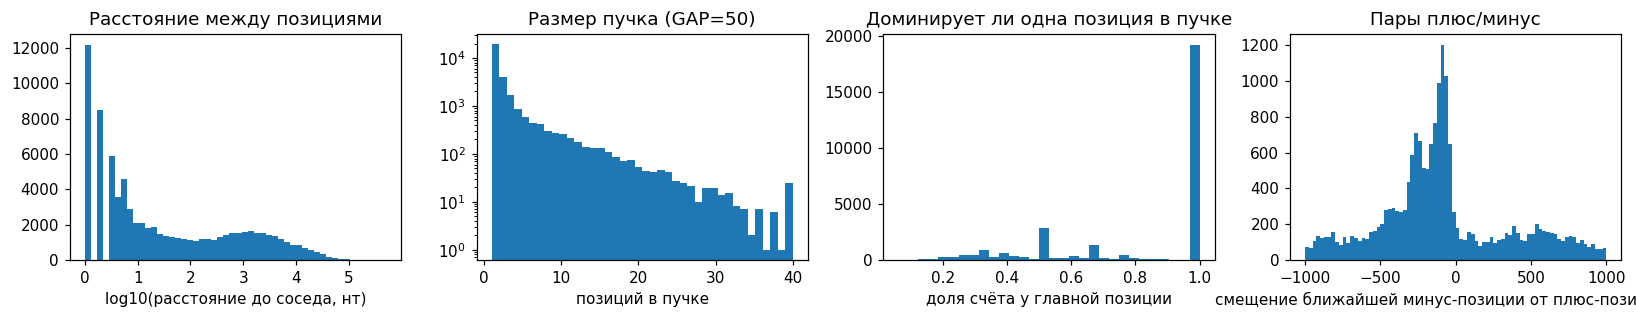

Как читать: если большинство позиций стоит рядом (<=5 нт) и счёт пучка размазан, строго «угадать нуклеотид» трудно, и AUPRC по позициям будет ограничен. Пик на гистограмме справа указывает на двунаправленную инициацию (дивергентные пары).


In [ ]:
GAP = 50     # позиции ближе GAP считаем одним пучком (кластером)
big = sorted(lab_contigs, key=lambda c: -len(codes[c]))[:3]
dists, sizes, top_share = [], [], []
offs = []
for c in big:
    per = {}
    for st in ("+", "-"):
        d = posrows[c][posrows[c].strand == st].sort_values("start")
        pos, tot = d.start.values, d.tot.values
        per[st] = pos
        if len(pos) < 2: continue
        gaps = np.diff(pos); dists.append(gaps)
        starts = np.flatnonzero(np.r_[True, gaps > GAP])
        sizes.append(np.diff(np.r_[starts, len(pos)]))
        top_share.append(np.maximum.reduceat(tot, starts) / np.add.reduceat(tot, starts))
    P, M = per.get("+", np.array([])), per.get("-", np.array([]))
    if len(P) and len(M):
        idx = np.searchsorted(M, P); lo, hi = M[np.clip(idx - 1, 0, len(M) - 1)] - P, M[np.clip(idx, 0, len(M) - 1)] - P
        near = np.where(np.abs(lo) < np.abs(hi), lo, hi); offs.append(near[np.abs(near) <= 1000])
dists, sizes, top_share, offs = map(np.concatenate, (dists, sizes, top_share, offs))
print(f"расстояние до соседней позиции на той же цепи: медиана {np.median(dists):.0f}, доля соседей на расстоянии <=5: {(dists<=5).mean():.1%}, <=50: {(dists<=50).mean():.1%}")
print(f"пучков при GAP={GAP}: {len(sizes)}; позиций в пучке: медиана {np.median(sizes):.0f}, пучков из одной позиции: {(sizes==1).mean():.1%}")
print(f"доля счёта пучка, приходящаяся на его самую сильную позицию: медиана {np.median(top_share):.2f}")

fig, ax = plt.subplots(1, 4, figsize=(15, 3))
ax[0].hist(np.log10(dists), bins=50); ax[0].set_xlabel("log10(расстояние до соседа, нт)"); ax[0].set_title("Расстояние между позициями")
ax[1].hist(np.clip(sizes, 0, 40), bins=40); ax[1].set_yscale("log"); ax[1].set_xlabel("позиций в пучке"); ax[1].set_title(f"Размер пучка (GAP={GAP})")
ax[2].hist(top_share, bins=30); ax[2].set_xlabel("доля счёта у главной позиции"); ax[2].set_title("Доминирует ли одна позиция в пучке")
ax[3].hist(offs, bins=80); ax[3].set_xlabel("смещение ближайшей минус-позиции от плюс-позиции, нт"); ax[3].set_title("Пары плюс/минус")
plt.tight_layout(); plt.show()
print("Как читать: если большинство позиций стоит рядом (<=5 нт) и счёт пучка размазан, строго «угадать нуклеотид» трудно, "
      "и AUPRC по позициям будет ограничен. Пик на гистограмме справа указывает на двунаправленную инициацию (дивергентные пары).")

пучков из >=3 позиций: 6372; ширина пучка (нт): медиана 39, 75% квантиль 63
доля счёта у главной позиции в таких пучках: медиана 0.40, доля пучков, где она >0.5: 25.0%


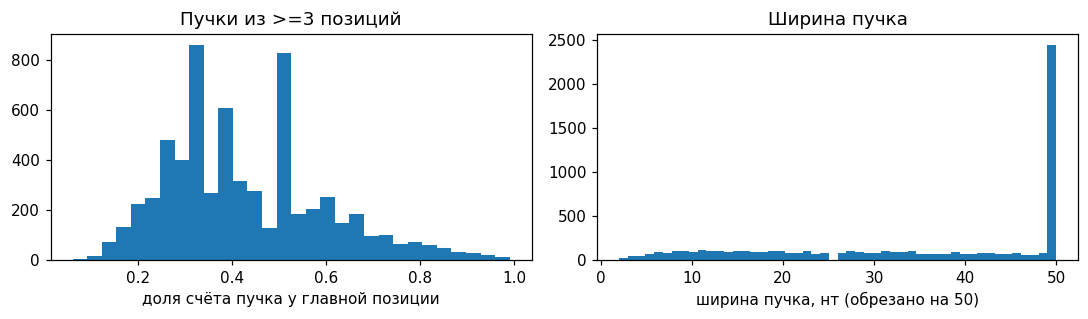

In [ ]:
# Уточнение раздела D: статистика только по пучкам из 3 и более позиций (в «доле главной позиции» одиночные пучки дают тривиальные 1.0)
sh, sz, span = [], [], []
for c in big:
    for st in ("+", "-"):
        d = posrows[c][posrows[c].strand == st].sort_values("start"); pos, tot = d.start.values, d.tot.values
        if len(pos) < 2: continue
        starts = np.flatnonzero(np.r_[True, np.diff(pos) > GAP]); ends = np.r_[starts[1:], len(pos)] - 1
        n_ = ends - starts + 1; keep = n_ >= 3
        sh.append((np.maximum.reduceat(tot, starts) / np.add.reduceat(tot, starts))[keep]); sz.append(n_[keep]); span.append((pos[ends] - pos[starts])[keep])
sh, sz, span = map(np.concatenate, (sh, sz, span))
print(f"пучков из >=3 позиций: {len(sz)}; ширина пучка (нт): медиана {np.median(span):.0f}, 75% квантиль {np.quantile(span, .75):.0f}")
print(f"доля счёта у главной позиции в таких пучках: медиана {np.median(sh):.2f}, доля пучков, где она >0.5: {(sh > .5).mean():.1%}")
fig, ax = plt.subplots(1, 2, figsize=(10, 3))
ax[0].hist(sh, bins=30); ax[0].set_xlabel("доля счёта пучка у главной позиции"); ax[0].set_title("Пучки из >=3 позиций")
ax[1].hist(np.clip(span, 0, 50), bins=50); ax[1].set_xlabel("ширина пучка, нт (обрезано на 50)"); ax[1].set_title("Ширина пучка")
plt.tight_layout(); plt.show()

### Как читать графики про пространственную структуру

Здесь «пучок» (кластер) это группа позиций одной цепи, соседние позиции в которой отстоят не более чем на 50 нт. Статистика считается по трём самым длинным хромосомам.

**График 1 («Расстояние между позициями»).** По оси X log10 расстояния до ближайшей позиции на той же цепи (0 значит 1 нт, 1 значит 10 нт, 3 значит 1000 нт), по оси Y число пар. Два горба: первый (расстояния 1–10 нт) это соседние позиции внутри одного пучка, медианное расстояние 10 нт, 41% соседей ближе 5 нт. Второй горб около 10³ (порядка 1 кб) это расстояние между разными пучками, например разными промоторами.

**График 2 («Размер пучка»).** По X число позиций в пучке, по Y число пучков (логарифмическая шкала). Из 29 510 пучков 65% состоят из одной позиции. Длинный хвост (до 40 и больше позиций) это широкие промоторы, где инициация размазана по участку.

**График 3 («Доминирует ли одна позиция в пучке»).** По X доля счёта пучка, приходящаяся на его главную позицию. Пик на 1,0 в основном тривиален: у пучка из одной позиции эта доля равна 1 по определению, а пик на 0,5 дают пары позиций с равным счётом. Поэтому честная статистика только по пучкам из трёх и более позиций, её считает ячейка выше.

**График 4 («Пары плюс/минус»).** Для каждой позиции на плюс-цепи берётся ближайшая позиция на минус-цепи; по X смещение (минус-позиция минус плюс-позиция), по Y число таких пар в пределах ±1000 нт. Пик справа налево от нуля, на отрицательных смещениях примерно от −100 до −300 нт. Это означает, что начало на минус-цепи обычно лежит на 100–300 нт левее начала на плюс-цепи, то есть транскрипция идёт в разные стороны от общего участка (двунаправленные, «дивергентные» промоторы). На положительных смещениях пика нет.

**Что это значит для модели.** (1) Позиции кучкуются, поэтому угадать именно нужный нуклеотид труднее, чем найти нужный участок: проверьте это ячейкой 18 основного ноутбука (толерантный AUPRC). (2) Начала на двух цепях связаны: появление начала на одной цепи повышает шанс начала на другой в 100–300 нт. Рецептивное поле нашей сети около 1000 нт, этого хватает, но можно связать выходы двух цепей явно.

## E. Последовательность вокруг позиций инициации
Строим «профиль мотивов»: частоты A, C, G, T в окне ±60 нт вокруг позиции. Для минус-цепи берём обратно-комплементарную последовательность, чтобы всегда читать в сторону транскрипции.
Сравниваем три группы: все позиции, одиночные (счёт 1), сильные (счёт ≥ 10). **Если у одиночных профиль плоский (как у фона), то они шумовые.**

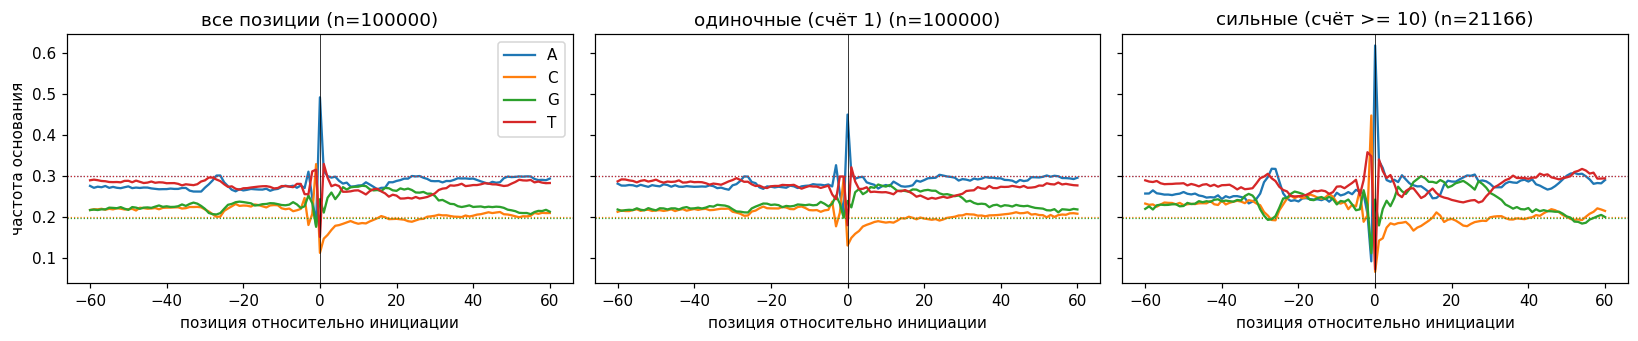

Как читать: пунктир — фоновая частота основания по геному. Пики и провалы рядом с нулём (обычно слабый мотив 'пиримидин-пурин' в позициях -1/0) и в районе -30 (TATA-подобный участок) говорят, что сигнал в последовательности есть. Если у одиночных позиций профиль почти совпадает с фоном, их стоит считать шумом (использовать порог счёта или меньший вес).


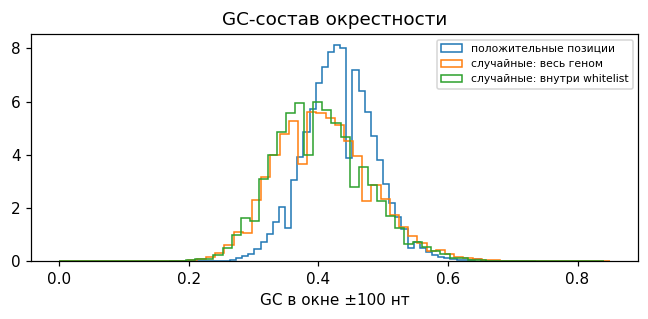

Как читать: если распределение положительных сдвинуто (например, в сторону высокого GC), то простой GC-признак уже отделяет их от фона, и часть качества модели может объясняться GC; whitelist сам может выбирать участки с особым GC.


In [ ]:
A_, B_ = 60, 60
def get_windows(x, p, strand, A, B):
    # окна из кодов 0-4 вокруг позиций p; индекс A окна = позиция инициации; для минус-цепи окно обратно-комплементарное
    L = len(x); W = A + B + 1; p = np.asarray(p)
    if strand == "+":
        p = p[(p >= A) & (p < L - B)]; return x[p[:, None] + np.arange(-A, B + 1)[None, :]]
    p = p[(p >= B) & (p < L - A)]; return COMP[x[p[:, None] + A - np.arange(W)[None, :]]]

def sample_windows(df_filter, n_max=100000, A=A_, B=B_, seed=0):
    out = []
    for c in lab_contigs:
        d = posrows[c]; d = d[df_filter(d)]
        for st in ("+", "-"):
            p = d[d.strand == st].start.values
            if len(p): out.append(get_windows(codes[c], p, st, A, B))
    W = np.concatenate(out); rs = np.random.RandomState(seed)
    return W[rs.permutation(len(W))[:n_max]]

groups = {"все позиции": lambda d: d.tot > 0, "одиночные (счёт 1)": lambda d: d.tot == 1, "сильные (счёт >= 10)": lambda d: d.tot >= 10}
bg = np.bincount(np.concatenate([codes[c][:2_000_000] for c in lab_contigs]), minlength=5)[:4]; bg = bg / bg.sum()
fig, ax = plt.subplots(1, 3, figsize=(15, 3.2), sharey=True)
for a, (name, fn) in zip(ax, groups.items()):
    Wn = sample_windows(fn)
    freqs = np.stack([(Wn == b).mean(0) / np.maximum((Wn < 4).mean(0), 1e-9) for b in range(4)])
    for b, nm in enumerate("ACGT"):
        a.plot(np.arange(-A_, B_ + 1), freqs[b], label=nm); a.axhline(bg[b], ls=":", color=f"C{b}", lw=0.8)
    a.axvline(0, color="k", lw=0.5); a.set_title(f"{name} (n={len(Wn)})"); a.set_xlabel("позиция относительно инициации")
ax[0].set_ylabel("частота основания"); ax[0].legend()
plt.tight_layout(); plt.show()
print("Как читать: пунктир — фоновая частота основания по геному. Пики и провалы рядом с нулём (обычно слабый мотив 'пиримидин-пурин' "
      "в позициях -1/0) и в районе -30 (TATA-подобный участок) говорят, что сигнал в последовательности есть. "
      "Если у одиночных позиций профиль почти совпадает с фоном, их стоит считать шумом (использовать порог счёта или меньший вес).")

# GC-состав окрестности ±100 нт: положительные позиции против случайных (во всём геноме и внутри whitelist)
def gc_window(c, pos, H=100):
    g = np.r_[0, np.cumsum(((codes[c] == 1) | (codes[c] == 2)).astype(np.int32))]
    pos = pos[(pos >= H) & (pos < len(codes[c]) - H)]
    return (g[pos + H + 1] - g[pos - H]) / (2 * H + 1)
rs = np.random.RandomState(1); gp, gr, gw = [], [], []
for c in lab_contigs:
    L = len(codes[c]); gp.append(gc_window(c, posrows[c].start.values))
    gr.append(gc_window(c, rs.randint(0, L, 100000)))
    wp = np.flatnonzero(inwl[c]); gw.append(gc_window(c, wp[rs.randint(0, len(wp), 100000)]))
fig, ax = plt.subplots(figsize=(6, 3))
for arr, nm in ((gp, "положительные позиции"), (gr, "случайные: весь геном"), (gw, "случайные: внутри whitelist")):
    ax.hist(np.concatenate(arr), bins=60, histtype="step", density=True, label=nm)
ax.set_xlabel("GC в окне ±100 нт"); ax.set_title("GC-состав окрестности"); ax.legend(fontsize=7)
plt.tight_layout(); plt.show()
print("Как читать: если распределение положительных сдвинуто (например, в сторону высокого GC), то простой GC-признак уже отделяет их от фона, "
      "и часть качества модели может объясняться GC; whitelist сам может выбирать участки с особым GC.")

### Как читать графики про последовательность

**Профиль оснований (три панели).** Для каждой группы позиций (все; только одиночные со счётом 1; только сильные со счётом ≥10) взяты окна ±60 нт вокруг позиции, для минус-цепи окно развёрнуто и дополнено, чтобы всегда читать в сторону транскрипции. По X смещение от позиции (0 это сама позиция инициации), по Y доля каждого основания (синий A, оранжевый C, зелёный G, красный T). Пунктиры это фоновая частота основания по геному (A и T около 0,30, C и G около 0,20: геном AT-богатый).

Что видно:
- **Все позиции:** в нуле резкий пик A (0,49 при фоне 0,30) и провал C, G и T. Рядом слева (позиция −1) подъём C и T. Это классическое «ядро» инициатора: пиримидин в −1 и A в 0.
- **Сильные позиции (≥10 прочтений):** тот же мотив гораздо резче: A в нуле достигает 0,62, а C в позиции −1 около 0,45 (против фона 0,20). Кроме того, около −30…−25 виден слабый подъём A и провал T и C: это TATA-подобный участок.
- **Одиночные позиции (счёт 1):** профиль похож на общий, но слабее (A в нуле 0,45), и подъёма около −27 нет. Значит, одиночные позиции не чистый шум: среди них много настоящих, но слабо используемых мест инициации, перемешанных с шумом.

**Что это значит для модели.** Сигнал в последовательности есть и у слабых, и у сильных позиций; у сильных он ярче, поэтому по силе предсказывать легче, чем по самому факту наличия одного прочтения. Выбрасывать одиночные позиции из обучения не нужно (они половина тестовых положительных), но можно снизить их вес в функции потерь.

**GC-график («GC-состав окрестности»).** По X доля G+C в окне ±100 нт вокруг позиции, по Y плотность. Три линии: положительные позиции; случайные позиции всего генома; случайные позиции внутри whitelist. Положительные сдвинуты вправо примерно на 4–6 процентных пунктов (пик около 0,43–0,45 против 0,37–0,40): промоторы лежат в окрестностях с повышенным GC. Линии случайных позиций (весь геном и whitelist) почти совпадают, значит, whitelist по GC не отбирает. Рваный контур у кривых это шум гистограммы (окно из 201 позиции и ограниченное число точек).

## F. Простой базовый уровень: матрица весов мотива (PWM) без нейросети
Берём окно вокруг положительных позиций train, считаем, насколько частоты оснований в каждой колонке отличаются от фона (логарифм отношения),
и оцениваем каждую позицию теста суммой этих логарифмов. Это самый простой «мотивный» метод.
Если он уже даёт заметную долю качества CNN, значит, много сигнала в коротком мотиве; если почти случайный, то весь выигрыш CNN идёт от более сложных признаков.
Оценка считается на тестовых интервалах из шаблона теми же метриками, что и раньше (AUPRC по всем позициям и Spearman в положительных).

In [ ]:
def pwm_llr(A, B, pseudo=1.0):
    W = A + B + 1; counts = np.zeros((5, W))
    for c in lab_contigs:
        d = posrows[c]
        for st in ("+", "-"):
            p = d[(d.strand == st) & (d.tot > 0)].start.values
            if len(p) == 0: continue
            win = get_windows(codes[c], p, st, A, B)
            for j in range(W): counts[:, j] += np.bincount(win[:, j], minlength=5)
    f = (counts[:4] + pseudo) / (counts[:4].sum(0) + 4 * pseudo)
    llr = np.zeros((5, W)); llr[:4] = np.log(f / bg[:, None])      # N даёт 0
    return llr

def conv_llr(x, llr, A):
    L = len(x); W = llr.shape[1]; S = np.zeros(L, np.float32)
    for j in range(W):
        off = j - A; a = llr[:, j].astype(np.float32)[x]
        if off >= 0: S[:L - off] += a[off:]
        else: S[-off:] += a[:L + off]
    return S

tcont = sorted(set(tb.chrom)); n_total = int(tb.len.sum())
def assemble_pwm(sc):
    return np.concatenate([sc[c][0 if st == "+" else 1][s:e] for c, s, e, st in zip(tb.chrom, tb.start, tb.end, tb.strand)])

def metrics(pred):
    y = gt > 0
    return {"AUPRC": round(float(average_precision_score(y, pred)), 4),
            "Spearman": round(float(spearmanr(pred[y], gt[y]).correlation), 4)}

print("случайный уровень AUPRC (доля положительных в тесте):", round(float((gt > 0).mean()), 5))
for A, B in ((10, 10), (40, 10)):
    llr = pwm_llr(A, B); sc = {}
    for c in tcont:
        x = codes[c]
        sc[c] = np.stack([conv_llr(x, llr, A), conv_llr(COMP[x][::-1].copy(), llr, A)[::-1]])   # плюс и минус цепь
    pred = assemble_pwm(sc)
    print(f"PWM окно [-{A}, +{B}] ({llr.shape[1]} колонок):", metrics(pred))

случайный уровень AUPRC (доля положительных в тесте): 0.00074
PWM окно [-10, +10] (21 колонок): {'AUPRC': 0.0018, 'Spearman': 0.1178}
PWM окно [-40, +10] (51 колонок): {'AUPRC': 0.0019, 'Spearman': 0.153}


### Как читать результат простого базового уровня (PWM)

PWM здесь это «мотивная» оценка без нейросети: берутся окна вокруг положительных позиций train (21 нт: −10…+10, и 51 нт: −40…+10), и по частотам оснований в каждой колонке строится сумма логарифмов отношения к фону. Каждая позиция теста получает такой счёт, по нему считаются те же метрики на тестовых интервалах.

| Метод | AUPRC | Spearman |
|---|---|---|
| случайный уровень | 0,00074 | — |
| PWM 21 нт | 0,0018 | 0,118 |
| PWM 51 нт | 0,0019 | 0,153 |
| наша CNN (из прошлого прогона) | 0,047 | 0,385 |

**Что это значит.** Один мотив (инициатор плюс TATA-подобный участок) даёт только 2,5 раза лучше случайного по AUPRC, а CNN около 60. То есть основная часть качества нашей модели берётся не из короткого мотива в позициях −40…+10, а из более широкого контекста (GC-состав окрестности, расположение относительно других участков, связь двух цепей). Поэтому расширять контекст сети и аккуратно подавать ей длинную последовательность должно быть полезнее, чем тонкая настройка локальных фильтров.

## Как превратить результаты EDA в решения (чек-лист)

1. **Реплики (B).** Запомните Spearman между репликами: это потолок. Если у нашей модели 0.39, а реплики дают, например, 0.5, то запас роста небольшой. Если реплики согласованы на 0.8, есть куда расти.
2. **Одиночные позиции (B, E).** Если у них нет мотивного профиля и они только в одной реплике, они в основном шум. Тогда пробуем: считать положительными только позиции с ≥2 прочтениями или присутствующие в обеих репликах (для обучения; метрику теста это не меняет), либо уменьшить вес таких позиций в loss.
3. **Whitelist (C).** Если плотность положительных внутри whitelist заметно выше и доли в train и тесте различаются, переключаем обучение и валидацию на позиции whitelist, чтобы val-метрика была сопоставима с тестовой.
4. **Маска повторов (A, C).** Если в fasta есть строчные буквы и whitelist от них отличается, добавляем маску пятым входным каналом (или просто исключаем повторы из выборки отрицательных примеров).
5. **Пучки (D).** Если позиции сильно кучкуются, добавляем к отчёту «толерантный AUPRC» (ячейка 18 основного ноутбука): он покажет, находит ли модель место приблизительно, но промахивается на несколько нуклеотидов.
6. **PWM (F).** Если PWM даёт долю качества CNN, то дальнейший прирост даёт расширение контекста и мультивидовое обучение; если почти ноль, то мотив слабый, и надо смотреть на более крупные масштабы (окно и рецептивное поле).

## Итоги EDA и что менять в модели (порядок по ожидаемой пользе)

**Что мы узнали о данных**
1. *Nematostella vectensis*: 15 хромосом (269 Мб) + 32 несобранных фрагмента без разметки. Обучаемся на 12 хромосомах, тестируемся на 3 (NC_064037.1, NC_064044.1, NC_064046.1).
2. Размеченные данные есть только внутри whitelist (62–77% каждой хромосомы); вне него это неизвестные участки, а не нули. Whitelist обогащён не-повторами (19% строчных внутри против 58% снаружи).
3. Тест размечен так же, как train (сумма двух реплик, 52% позиций со счётом 1) и имеет почти ту же долю положительных внутри whitelist (7,4·10⁻⁴ против 7,1·10⁻⁴).
4. Метки шумные: 52% позиций со счётом 1, 79% позиций объединения замечены только одной репликой. Но сигнал в последовательности есть и у слабых позиций.
5. Позиции кучкуются (41% соседей ближе 5 нт), а начала на плюс- и минус-цепях часто образуют дивергентные пары на расстоянии 100–300 нт.
6. Мотив инициатора (C/T в −1, A в 0) есть, но один он даёт только AUPRC 0,002 (в 2,5 раза выше случайного); CNN даёт 0,047, значит, ей помогает широкий контекст.

**Что менять в модели**
1. **Маска функции потерь по whitelist.** Считать BCE и регрессию только на позициях whitelist (вне него метка неизвестна), а негативные окна брать только оттуда. Валидировать только на whitelist-позициях, тогда val-метрика станет сопоставимой с тестом. Это самое дешёвое и самое вероятное улучшение.
2. **Валидация по нескольким хромосомам.** Сейчас val это 10% длины, примерно одна хромосома. Лучше 3–4 хромосомы или перекрёстная проверка по хромосомам, иначе сравнения между вариантами шумные.
3. **Расширить контекст.** Увеличить окно (4096–8192) и рецептивное поле (дилатации до 1024 и выше): PWM показала, что локального мотива мало.
4. **Мягкие метки по репликам.** Вместо 0/1 использовать долю реплик с сигналом (0, 0,5, 1) как цель для наличия: это снижает шум обучающих меток, не меняя определения тестовой метки.
5. **Маска повторов** (строчные буквы) как пятый канал входа: даёт модели ту же информацию, по которой whitelist вырезает участки.
6. **Позже:** ансамбль нескольких сидов; затем остальные виды с общим телом сети.